# PhishGuard AI — Milestone 3: Dataset Audit

This notebook audits a local screenshot dataset before OCR or computer vision development. It reads images directly from `PhishGuard/data/phishing` and `PhishGuard/data/legitimate`, records issues and duplicates, and writes reports under `PhishGuard/reports`. It never edits or deletes source images.

**Setup:** Install dependencies if needed: `pip install pandas numpy pillow matplotlib seaborn ImageHash`. Run cells from top to bottom. The project root is discovered automatically when a `PhishGuard` folder is an ancestor or nearby; if discovery fails, set `PROJECT_ROOT` in Section 1.


## 1. Environment Setup & Imports

This section imports only the libraries needed for file scanning, image inspection, hashing, tables, and plots. It locates the local project folders, creates the report folder, and checks that both class folders exist. Path discovery keeps the notebook portable across Windows and other local Jupyter environments.


In [2]:
!pip install pandas numpy pillow matplotlib seaborn ImageHash

In [1]:
from pathlib import Path
import hashlib
import json
import os
import warnings

import numpy as np
import pandas as pd
from PIL import Image, ImageFile, UnidentifiedImageError
import matplotlib.pyplot as plt
import seaborn as sns

try:
    import imagehash
except ImportError as exc:
    raise ImportError("ImageHash is required for pHash. Install it with: pip install ImageHash") from exc

# Automatically locate the project using the data folder structure
PROJECT_ROOT = Path.cwd().resolve()

found = None

for start in [PROJECT_ROOT, *PROJECT_ROOT.parents]:
    if (
        (start / "data" / "phishing").is_dir()
        and (start / "data" / "legitimate").is_dir()
    ):
        found = start
        break

if found is None:
    raise FileNotFoundError(
        f"Could not find the dataset folders.\n"
        f"Current directory: {Path.cwd()}\n"
        "Expected structure: data/phishing and data/legitimate"
    )

PROJECT_ROOT = found

DATA_DIR = PROJECT_ROOT / "data"
REPORTS_DIR = PROJECT_ROOT / "reports"
PHISHING_DIR = DATA_DIR / "phishing"
LEGITIMATE_DIR = DATA_DIR / "legitimate"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

for class_dir in (PHISHING_DIR, LEGITIMATE_DIR):
    if not class_dir.is_dir():
        raise FileNotFoundError(f"Required class directory not found: {class_dir}")

IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".webp", ".bmp", ".tif", ".tiff"}
print(f"Project root: {PROJECT_ROOT}")
print(f"Reports directory: {REPORTS_DIR}")


Project root: D:\DEPI Graduation Project\computer_vision_milstone
Reports directory: D:\DEPI Graduation Project\computer_vision_milstone\reports


## 2. Dataset Loading & Manifest Creation

The folders are scanned recursively for supported image formats. Each discovered file becomes one manifest row with a stable record ID, class label, path, filename, and file size. This inventory establishes a traceable baseline without moving or changing any image.


In [2]:
records = []
for label, class_dir in (("phishing", PHISHING_DIR), ("legitimate", LEGITIMATE_DIR)):
    for path in sorted(class_dir.rglob("*")):
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
            try:
                size_bytes = path.stat().st_size
            except OSError:
                size_bytes = None
            records.append({
                "record_id": len(records) + 1,
                "image_id": f"img_{len(records) + 1:06d}",
                "path": str(path.resolve()),
                "label": label,
                "file_name": path.name,
                "file_size_bytes": size_bytes,
            })

manifest = pd.DataFrame(records, columns=[
    "record_id", "image_id", "path", "label", "file_name", "file_size_bytes"
])
print(f"Discovered image files: {len(manifest):,}")
display(manifest.head())


Discovered image files: 19,850


,record_id,image_id,path,label,file_name,file_size_bytes
0,1,img_000001,D:\DEPI Graduation Project\computer_vision_mil...,phishing,10010_qrco.de_bfWgu0.png,94567
1,2,img_000002,D:\DEPI Graduation Project\computer_vision_mil...,phishing,10015_qrco.de_bfHe0H.png,94567
2,3,img_000003,D:\DEPI Graduation Project\computer_vision_mil...,phishing,10021_q-r.to_bfJnIk.png,36318
3,4,img_000004,D:\DEPI Graduation Project\computer_vision_mil...,phishing,10030_linkin.bio_bankaxept.png,689150
4,5,img_000005,D:\DEPI Graduation Project\computer_vision_mil...,phishing,10037_qrco.de_bfO5Oe.png,56333


## 3. Dataset Overview & Class Distribution

This section counts images per class, computes their percentages, and plots the distribution. Class balance matters because a large difference in class counts can bias later model development and evaluation. A difference of more than 10 percentage points is flagged as imbalanced as a simple audit heuristic.


,count,percentage
label,,
phishing,6109,30.775819
legitimate,13741,69.224181


Total images: 19,850
Assessment: imbalanced (class percentage gap > 10 points)


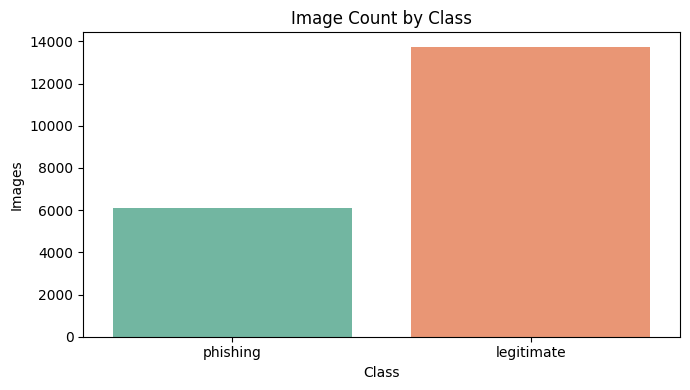

In [3]:
total_images = len(manifest)
class_counts = manifest["label"].value_counts().reindex(["phishing", "legitimate"], fill_value=0)
class_percentages = (class_counts / total_images * 100) if total_images else class_counts.astype(float)
class_distribution = pd.DataFrame({"count": class_counts, "percentage": class_percentages})
display(class_distribution)
print(f"Total images: {total_images:,}")
if total_images:
    gap = float(class_percentages.max() - class_percentages.min())
    print("Assessment:", "imbalanced (class percentage gap > 10 points)" if gap > 10 else "approximately balanced (class percentage gap <= 10 points)")
else:
    print("Assessment: no supported images were discovered.")

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=class_counts.index, y=class_counts.values, hue=class_counts.index, legend=False, palette="Set2", ax=ax)
ax.set(title="Image Count by Class", xlabel="Class", ylabel="Images")
plt.tight_layout()
plt.show()


## 4. Image Validation & Integrity Check

Each image is opened and fully decoded individually. Failures are recorded so one damaged file does not stop the audit. The section records dimensions, mode, readability, error details, and whether every pixel is white. Fully white screenshots contain no useful visual content and are excluded from the cleaned manifest.


In [7]:

from PIL import Image, ImageFile
import numpy as np
import pandas as pd
import time

ImageFile.LOAD_TRUNCATED_IMAGES = False

validation_rows = []
total = len(manifest)

start_time = time.perf_counter()

for i, row in enumerate(manifest.itertuples(index=False), start=1):

    result = {
        "image_id": row.image_id,
        "width": np.nan,
        "height": np.nan,
        "image_mode": None,
        "readable": False,
        "is_fully_white": False,
        "validation_error": None
    }

    try:
        with Image.open(row.path) as img:
            img.load()

            result["width"], result["height"] = img.size
            result["image_mode"] = img.mode

            extrema = img.getextrema()

            if isinstance(extrema[0], tuple):
                result["is_fully_white"] = all(
                    low == high == (
                        1 if band == "1" else 255
                    )
                    for band, (low, high) in zip(
                        img.getbands(), extrema
                    )
                )
            else:
                maximum = 1 if img.mode == "1" else 255
                result["is_fully_white"] = (
                    extrema[0] == maximum
                    and extrema[1] == maximum
                )

            result["readable"] = True

    except Exception as exc:
        result["validation_error"] = (
            f"{type(exc).__name__}: {exc}"
        )

    validation_rows.append(result)

    # Print progress every 100 images
    if i % 100 == 0 or i == total:
        elapsed = time.perf_counter() - start_time
        percentage = (i / total) * 100

        print(
            f"Processed: {i:,}/{total:,} "
            f"({percentage:.1f}%) | "
            f"Time: {elapsed:.1f}s",
            flush=True
        )

validation_df = pd.DataFrame(validation_rows)

manifest = manifest.merge(
    validation_df,
    on="image_id",
    how="left",
    validate="one_to_one"
)

readable_count = int(manifest["readable"].fillna(False).sum())
unreadable_count = total - readable_count

white_count = int(
    (
        manifest["readable"].fillna(False)
        & manifest["is_fully_white"].fillna(False)
    ).sum()
)

print("\nIMAGE VALIDATION SUMMARY")
print(f"Total images: {total:,}")
print(f"Readable: {readable_count:,}")
print(f"Unreadable: {unreadable_count:,}")
print(f"Fully white: {white_count:,}")

if unreadable_count:
    display(
        manifest.loc[
            ~manifest["readable"].fillna(False),
            ["image_id", "path", "validation_error"]
        ]
    )


Processed: 100/19,850 (0.5%) | Time: 2.1s
Processed: 200/19,850 (1.0%) | Time: 4.0s
Processed: 300/19,850 (1.5%) | Time: 6.1s
Processed: 400/19,850 (2.0%) | Time: 8.1s
Processed: 500/19,850 (2.5%) | Time: 10.1s
Processed: 600/19,850 (3.0%) | Time: 12.0s
Processed: 700/19,850 (3.5%) | Time: 13.9s
Processed: 800/19,850 (4.0%) | Time: 15.8s
Processed: 900/19,850 (4.5%) | Time: 17.8s
Processed: 1,000/19,850 (5.0%) | Time: 19.7s
Processed: 1,100/19,850 (5.5%) | Time: 23.0s
Processed: 1,200/19,850 (6.0%) | Time: 27.1s
Processed: 1,300/19,850 (6.5%) | Time: 30.3s
Processed: 1,400/19,850 (7.1%) | Time: 32.4s
Processed: 1,500/19,850 (7.6%) | Time: 34.5s
Processed: 1,600/19,850 (8.1%) | Time: 36.6s
Processed: 1,700/19,850 (8.6%) | Time: 38.5s
Processed: 1,800/19,850 (9.1%) | Time: 40.1s
Processed: 1,900/19,850 (9.6%) | Time: 41.1s
Processed: 2,000/19,850 (10.1%) | Time: 42.3s
Processed: 2,100/19,850 (10.6%) | Time: 43.4s
Processed: 2,200/19,850 (11.1%) | Time: 44.5s
Processed: 2,300/19,850 (11.6

,image_id,path,validation_error
1886,img_001887,D:\DEPI Graduation Project\computer_vision_mil...,UnidentifiedImageError: cannot identify image ...
2093,img_002094,D:\DEPI Graduation Project\computer_vision_mil...,UnidentifiedImageError: cannot identify image ...
2187,img_002188,D:\DEPI Graduation Project\computer_vision_mil...,UnidentifiedImageError: cannot identify image ...
2775,img_002776,D:\DEPI Graduation Project\computer_vision_mil...,UnidentifiedImageError: cannot identify image ...
3031,img_003032,D:\DEPI Graduation Project\computer_vision_mil...,UnidentifiedImageError: cannot identify image ...
3035,img_003036,D:\DEPI Graduation Project\computer_vision_mil...,UnidentifiedImageError: cannot identify image ...
3081,img_003082,D:\DEPI Graduation Project\computer_vision_mil...,UnidentifiedImageError: cannot identify image ...
3156,img_003157,D:\DEPI Graduation Project\computer_vision_mil...,UnidentifiedImageError: cannot identify image ...
3351,img_003352,D:\DEPI Graduation Project\computer_vision_mil...,UnidentifiedImageError: cannot identify image ...
3405,img_003406,D:\DEPI Graduation Project\computer_vision_mil...,UnidentifiedImageError: cannot identify image ...


## 5. Image Properties Analysis

Readable images are summarized by dimensions, modes, file sizes, and aspect ratios, with plots for their distributions. These properties reveal inconsistent captures or outliers that may affect later preprocessing. All values are derived from successfully decoded images only.


,count,mean,std,min,25%,50%,75%,max
width,19832.0,1573.892194,323.214396,709.000000,1280.000000,1280.000000,1920.000000,7.818000e+03
height,19832.0,1015.241579,87.635438,467.000000,960.000000,960.000000,1080.000000,7.948000e+03
aspect_ratio,19832.0,1.537747,0.222174,0.245596,1.333333,1.333333,1.777778,2.144691e+00
file_size_bytes,19832.0,422599.407372,472798.829675,6230.000000,103501.250000,257903.000000,555136.000000,1.610704e+07


,count
image_mode,
RGB,19727
RGBA,105


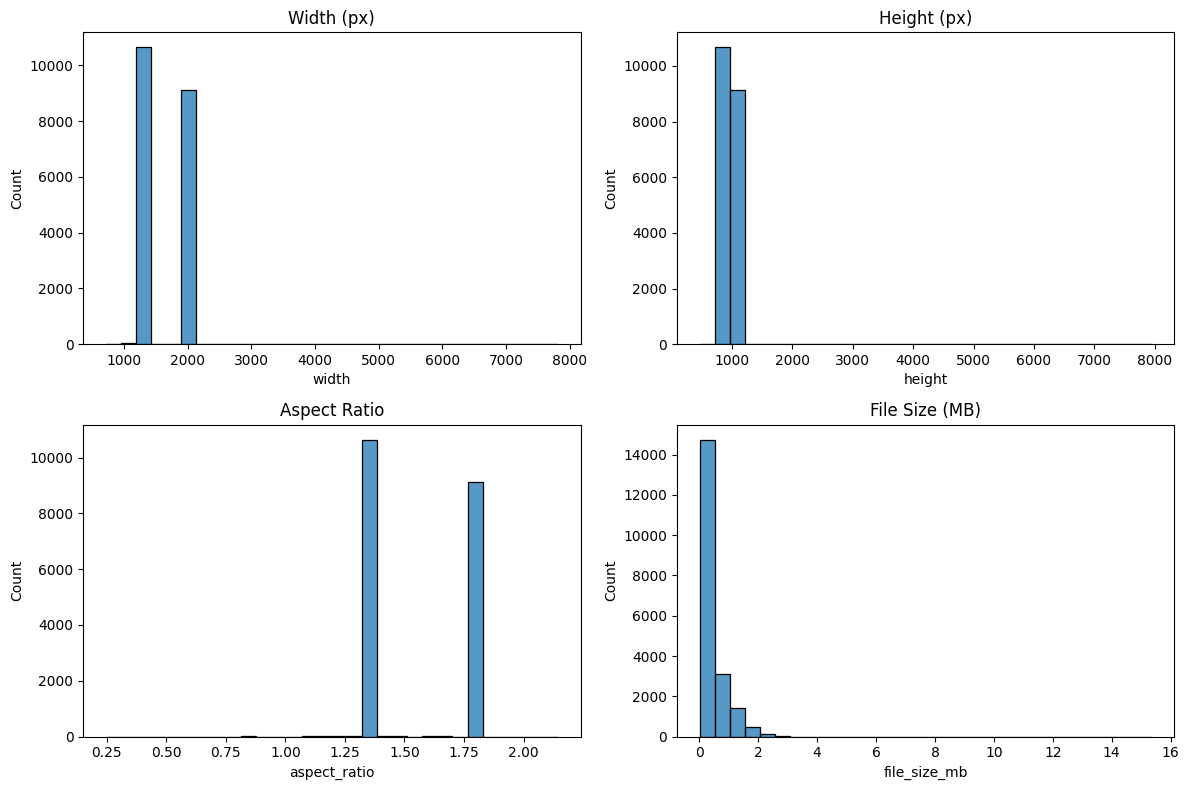

In [8]:
readable_df = manifest.loc[manifest["readable"].fillna(False)].copy()
readable_df["aspect_ratio"] = readable_df["width"] / readable_df["height"].replace(0, np.nan)
readable_df["file_size_mb"] = readable_df["file_size_bytes"] / (1024 ** 2)
property_columns = ["width", "height", "aspect_ratio", "file_size_bytes"]
if len(readable_df):
    display(readable_df[property_columns].describe().T)
    display(readable_df["image_mode"].value_counts(dropna=False).rename_axis("image_mode").to_frame("count"))
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    sns.histplot(readable_df["width"], bins=30, ax=axes[0, 0]); axes[0, 0].set_title("Width (px)")
    sns.histplot(readable_df["height"], bins=30, ax=axes[0, 1]); axes[0, 1].set_title("Height (px)")
    sns.histplot(readable_df["aspect_ratio"].dropna(), bins=30, ax=axes[1, 0]); axes[1, 0].set_title("Aspect Ratio")
    sns.histplot(readable_df["file_size_mb"].dropna(), bins=30, ax=axes[1, 1]); axes[1, 1].set_title("File Size (MB)")
    plt.tight_layout(); plt.show()
else:
    print("No readable images are available for property analysis.")


## 6. Exact Duplicate Detection (SHA256)

SHA256 is calculated by streaming each readable file in chunks, avoiding loading the full dataset into memory. Identical hashes indicate byte-for-byte duplicates. Groups are also checked for conflicting class labels, which can create label leakage or contradictory training examples.


In [9]:
def sha256_file(file_path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()
    with open(file_path, "rb") as file_obj:
        for chunk in iter(lambda: file_obj.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()

manifest["sha256"] = pd.NA
for idx, row in manifest.loc[manifest["readable"].fillna(False)].iterrows():
    try:
        manifest.at[idx, "sha256"] = sha256_file(row["path"])
    except OSError as exc:
        # A file that becomes inaccessible after validation is retained with no hash and reported.
        manifest.at[idx, "validation_error"] = f"Hash error: {type(exc).__name__}: {exc}"
        manifest.at[idx, "readable"] = False

hashable = manifest.dropna(subset=["sha256"])
exact_groups = {h: grp for h, grp in hashable.groupby("sha256") if len(grp) > 1}
conflicting_hashes = {h for h, grp in exact_groups.items() if grp["label"].nunique() > 1}
unique_hash_count = int(hashable["sha256"].nunique())
exact_duplicate_group_count = len(exact_groups)
images_in_exact_duplicate_groups = int(sum(len(g) for g in exact_groups.values()))
conflicting_label_group_count = len(conflicting_hashes)
images_in_conflicting_label_groups = int(sum(len(exact_groups[h]) for h in conflicting_hashes))
print(f"Unique SHA256 hashes: {unique_hash_count:,}")
print(f"Exact duplicate groups: {exact_duplicate_group_count:,}; images in groups: {images_in_exact_duplicate_groups:,}")
print(f"Conflicting-label groups: {conflicting_label_group_count:,}; images in groups: {images_in_conflicting_label_groups:,}")


Unique SHA256 hashes: 15,189
Exact duplicate groups: 3,038; images in groups: 7,681
Conflicting-label groups: 5; images in groups: 209


## 7. Near-Duplicate Detection (pHash)

Perceptual hashes capture visual similarity even when file bytes differ. Each readable, hashable image is opened one at a time to calculate pHash, and candidate pairs are compared using Hamming distance with a configurable threshold. Pairwise comparison can be computationally expensive as the dataset grows; this implementation uses compact integer hashes and skips pairs beyond the threshold bit-count check. Candidates are only reported for manual review and are never removed automatically.


In [10]:
PHASH_DISTANCE_THRESHOLD = 5
manifest["phash"] = pd.NA
eligible_indices = manifest.index[manifest["readable"].fillna(False) & manifest["sha256"].notna()].tolist()
phash_ints = []  # Small integer representation, one per eligible image.
phash_meta = []
for idx in eligible_indices:
    try:
        with Image.open(manifest.at[idx, "path"]) as img:
            img.load()
            phash_hex = str(imagehash.phash(img))
        manifest.at[idx, "phash"] = phash_hex
        phash_ints.append(int(phash_hex, 16))
        phash_meta.append(idx)
    except Exception as exc:
        manifest.at[idx, "validation_error"] = f"pHash error: {type(exc).__name__}: {exc}"

near_pairs = []
# Use integer XOR bit counts; still O(n^2), but avoids repeated image decoding and object creation.
for i in range(len(phash_ints)):
    hash_i = phash_ints[i]
    idx_i = phash_meta[i]
    for j in range(i + 1, len(phash_ints)):
        distance = (hash_i ^ phash_ints[j]).bit_count()
        if distance <= PHASH_DISTANCE_THRESHOLD:
            idx_j = phash_meta[j]
            near_pairs.append({
                "image_id_1": manifest.at[idx_i, "image_id"],
                "label_1": manifest.at[idx_i, "label"],
                "path_1": manifest.at[idx_i, "path"],
                "image_id_2": manifest.at[idx_j, "image_id"],
                "label_2": manifest.at[idx_j, "label"],
                "path_2": manifest.at[idx_j, "path"],
                "hamming_distance": distance,
            })
near_duplicates_df = pd.DataFrame(near_pairs, columns=[
    "image_id_1", "label_1", "path_1", "image_id_2", "label_2", "path_2", "hamming_distance"
])
images_with_phash = int(manifest["phash"].notna().sum())
print(f"Images with pHash: {images_with_phash:,}")
print(f"Candidate near-duplicate pairs (distance <= {PHASH_DISTANCE_THRESHOLD}): {len(near_duplicates_df):,}")
display(near_duplicates_df.head(20))


Images with pHash: 19,832
Candidate near-duplicate pairs (distance <= 5): 215,875


,image_id_1,label_1,path_1,image_id_2,label_2,path_2,hamming_distance
0,img_000001,phishing,D:\DEPI Graduation Project\computer_vision_mil...,img_000002,phishing,D:\DEPI Graduation Project\computer_vision_mil...,0
1,img_000001,phishing,D:\DEPI Graduation Project\computer_vision_mil...,img_000007,phishing,D:\DEPI Graduation Project\computer_vision_mil...,0
2,img_000001,phishing,D:\DEPI Graduation Project\computer_vision_mil...,img_000013,phishing,D:\DEPI Graduation Project\computer_vision_mil...,0
3,img_000001,phishing,D:\DEPI Graduation Project\computer_vision_mil...,img_000015,phishing,D:\DEPI Graduation Project\computer_vision_mil...,0
4,img_000001,phishing,D:\DEPI Graduation Project\computer_vision_mil...,img_000017,phishing,D:\DEPI Graduation Project\computer_vision_mil...,0
5,img_000001,phishing,D:\DEPI Graduation Project\computer_vision_mil...,img_000025,phishing,D:\DEPI Graduation Project\computer_vision_mil...,0
6,img_000001,phishing,D:\DEPI Graduation Project\computer_vision_mil...,img_000026,phishing,D:\DEPI Graduation Project\computer_vision_mil...,0
7,img_000001,phishing,D:\DEPI Graduation Project\computer_vision_mil...,img_000031,phishing,D:\DEPI Graduation Project\computer_vision_mil...,0
8,img_000001,phishing,D:\DEPI Graduation Project\computer_vision_mil...,img_000040,phishing,D:\DEPI Graduation Project\computer_vision_mil...,0
9,img_000001,phishing,D:\DEPI Graduation Project\computer_vision_mil...,img_000043,phishing,D:\DEPI Graduation Project\computer_vision_mil...,0


## 8. Duplicate Review & Clean Manifest

The cleaned manifest is a DataFrame view of the audit decisions, not a change to source files. It excludes unreadable and fully white images, removes every member of conflicting-label exact duplicate groups, and keeps one representative from each remaining same-label exact duplicate group. Near-duplicate candidates remain untouched for human inspection.


In [11]:
valid_mask = manifest["readable"].fillna(False) & ~manifest["is_fully_white"].fillna(False)
conflict_mask = manifest["sha256"].isin(conflicting_hashes)
pre_exact_clean = manifest.loc[valid_mask & ~conflict_mask].copy()
# Keep the first stable manifest row for each exact byte-identical image.
cleaned_df = pre_exact_clean.sort_values("record_id").drop_duplicates(subset=["sha256"], keep="first").copy()

unreadable_excluded = int((~manifest["readable"].fillna(False)).sum())
white_excluded = int((manifest["readable"].fillna(False) & manifest["is_fully_white"].fillna(False)).sum())
conflicting_images_excluded = int((valid_mask & conflict_mask).sum())
exact_duplicate_copies_removed = int(len(pre_exact_clean) - len(cleaned_df))
cleaned_class_counts = cleaned_df["label"].value_counts().reindex(["phishing", "legitimate"], fill_value=0)
print(f"Original images: {len(manifest):,}")
print(f"Unreadable excluded: {unreadable_excluded:,}")
print(f"Fully white excluded: {white_excluded:,}")
print(f"Conflicting-label images excluded: {conflicting_images_excluded:,}")
print(f"Exact duplicate copies removed: {exact_duplicate_copies_removed:,}")
print(f"Final cleaned dataset size: {len(cleaned_df):,}")
display(cleaned_class_counts.rename("count").to_frame())
print("Near-duplicate candidates were retained for manual visual inspection.")


Original images: 19,850
Unreadable excluded: 18
Fully white excluded: 169
Conflicting-label images excluded: 40
Exact duplicate copies removed: 4,439
Final cleaned dataset size: 15,184


,count
label,
phishing,4752
legitimate,10432


Near-duplicate candidates were retained for manual visual inspection.


## 9. Final Dataset Summary & Audit Report

This final section consolidates counts and class distribution, displays the audit summary, and saves the full manifest, cleaned manifest, near-duplicate pairs, and summary tables as CSV and JSON under `reports/`. These reports make the audit reproducible and reviewable. No image files are modified.


In [12]:
summary = {
    "project_root": str(PROJECT_ROOT),
    "total_discovered_images": int(len(manifest)),
    "readable_images": int(manifest["readable"].fillna(False).sum()),
    "unreadable_images": int((~manifest["readable"].fillna(False)).sum()),
    "fully_white_images": int((manifest["readable"].fillna(False) & manifest["is_fully_white"].fillna(False)).sum()),
    "unique_sha256_hashes": int(manifest["sha256"].nunique()),
    "exact_duplicate_groups": int(exact_duplicate_group_count),
    "images_in_exact_duplicate_groups": int(images_in_exact_duplicate_groups),
    "conflicting_label_groups": int(conflicting_label_group_count),
    "images_in_conflicting_label_groups": int(images_in_conflicting_label_groups),
    "images_with_phash": int(images_with_phash),
    "near_duplicate_candidate_pairs": int(len(near_duplicates_df)),
    "phash_hamming_distance_threshold": int(PHASH_DISTANCE_THRESHOLD),
    "final_cleaned_dataset_size": int(len(cleaned_df)),
    "final_class_distribution": {k: int(v) for k, v in cleaned_class_counts.items()},
}
summary_df = pd.DataFrame([summary])

manifest.to_csv(REPORTS_DIR / "dataset_audit_manifest.csv", index=False, encoding="utf-8-sig")
cleaned_df.to_csv(REPORTS_DIR / "cleaned_image_manifest.csv", index=False, encoding="utf-8-sig")
near_duplicates_df.to_csv(REPORTS_DIR / "near_duplicate_candidates.csv", index=False, encoding="utf-8-sig")
summary_df.to_csv(REPORTS_DIR / "dataset_summary.csv", index=False, encoding="utf-8-sig")
with open(REPORTS_DIR / "dataset_audit_summary.json", "w", encoding="utf-8") as file_obj:
    json.dump(summary, file_obj, indent=2, ensure_ascii=False)

display(summary_df.T.rename(columns={0: "value"}))
print(f"Reports saved to: {REPORTS_DIR}")


,value
project_root,D:\DEPI Graduation Project\computer_vision_mil...
total_discovered_images,19850
readable_images,19832
unreadable_images,18
fully_white_images,169
unique_sha256_hashes,15189
exact_duplicate_groups,3038
images_in_exact_duplicate_groups,7681
conflicting_label_groups,5
images_in_conflicting_label_groups,209


Reports saved to: D:\DEPI Graduation Project\computer_vision_milstone\reports


In [14]:
# Check conflicting groups
conflict_groups = (
    manifest.groupby("sha256")
    .filter(lambda group: group["label"].nunique() > 1)
)

print("Images in conflicting groups:", len(conflict_groups))
print("Unique conflicting hashes:", conflict_groups["sha256"].nunique())

# Check which conflicting images remain in the clean manifest
remaining_conflicts = cleaned_df[
    cleaned_df["sha256"].isin(
        conflict_groups["sha256"].unique()
    )
]

print("Conflicting images remaining:", len(remaining_conflicts))

Images in conflicting groups: 209
Unique conflicting hashes: 5
Conflicting images remaining: 0


In [17]:
print("Original manifest:", len(manifest))
print("Cleaned dataset:", len(cleaned_df))

print("\nRemaining unreadable images:",
      (~cleaned_df["readable"]).sum())

print("\nRemaining fully white images:",
      cleaned_df["is_fully_white"].sum())

print("\nRemaining conflicting-label groups:",
      cleaned_df.groupby("sha256")["label"].nunique().gt(1).sum())

print("\nRemaining exact duplicate groups:",
      (cleaned_df["sha256"].value_counts() > 1).sum())

print("\nFinal class distribution:")
display(cleaned_df["label"].value_counts())

Original manifest: 19850
Cleaned dataset: 15184

Remaining unreadable images: 0

Remaining fully white images: 0

Remaining conflicting-label groups: 0

Remaining exact duplicate groups: 0

Final class distribution:


label
legitimate    10432
phishing       4752
Name: count, dtype: int64